# Re-ranking retrieval results with TypeSafe

You have thousands of documents, and you need to find the one that answers a specific
question.

First, use a quick method such as keyword matching to cut those thousands of candidates
down to a shortlist of plausible ones. We call this fast search.

Fast search is good at that, but it can't tell you which candidate on the shortlist is
correct. That's where re-ranking comes in. It scores every candidate on the shortlist
against the query directly, and puts the best one first.

Both steps run below on 3,565 court opinion passages from the CLERC dataset: BM25 builds a
fast search shortlist of 30 candidates for each of 40 queries, then Jev re-ranks each
shortlist. With re-ranking, the correct passage lands in first place for 30% of queries, up
from 5% with fast search alone.

## How do we find one document in thousands?

Checking every document against the query, one at a time, takes one comparison per
document: millions of documents means millions of comparisons per query. Two steps are
faster:

1. Cut the pile down to a short list of likely candidates, using a method fast enough to
   run on the whole pile.
2. Apply a more accurate step to that short list, to find the exact right answer.

Animated diagram: a pile of documents narrows to a fast search shortlist, then re-ranking
reorders that shortlist so the correct answer rises to the
top

## What is fast search?

Fast search is any method that can compare a query against every document in a large corpus
and quickly return a ranked shortlist. Common methods include keyword search, such as BM25,
and dense embeddings, which compare passages by meaning.

The first step here is BM25 and nothing else. BM25 ranks passages by shared words.
The choice of fast search method is a side issue: re-ranking only ever sees the passages
that make the shortlist.

## What is re-ranking?

Re-ranking puts the shortlist in a better order. Instead of comparing the query against
the whole corpus at once, it scores the query against each candidate on the shortlist and
sorts by that score.

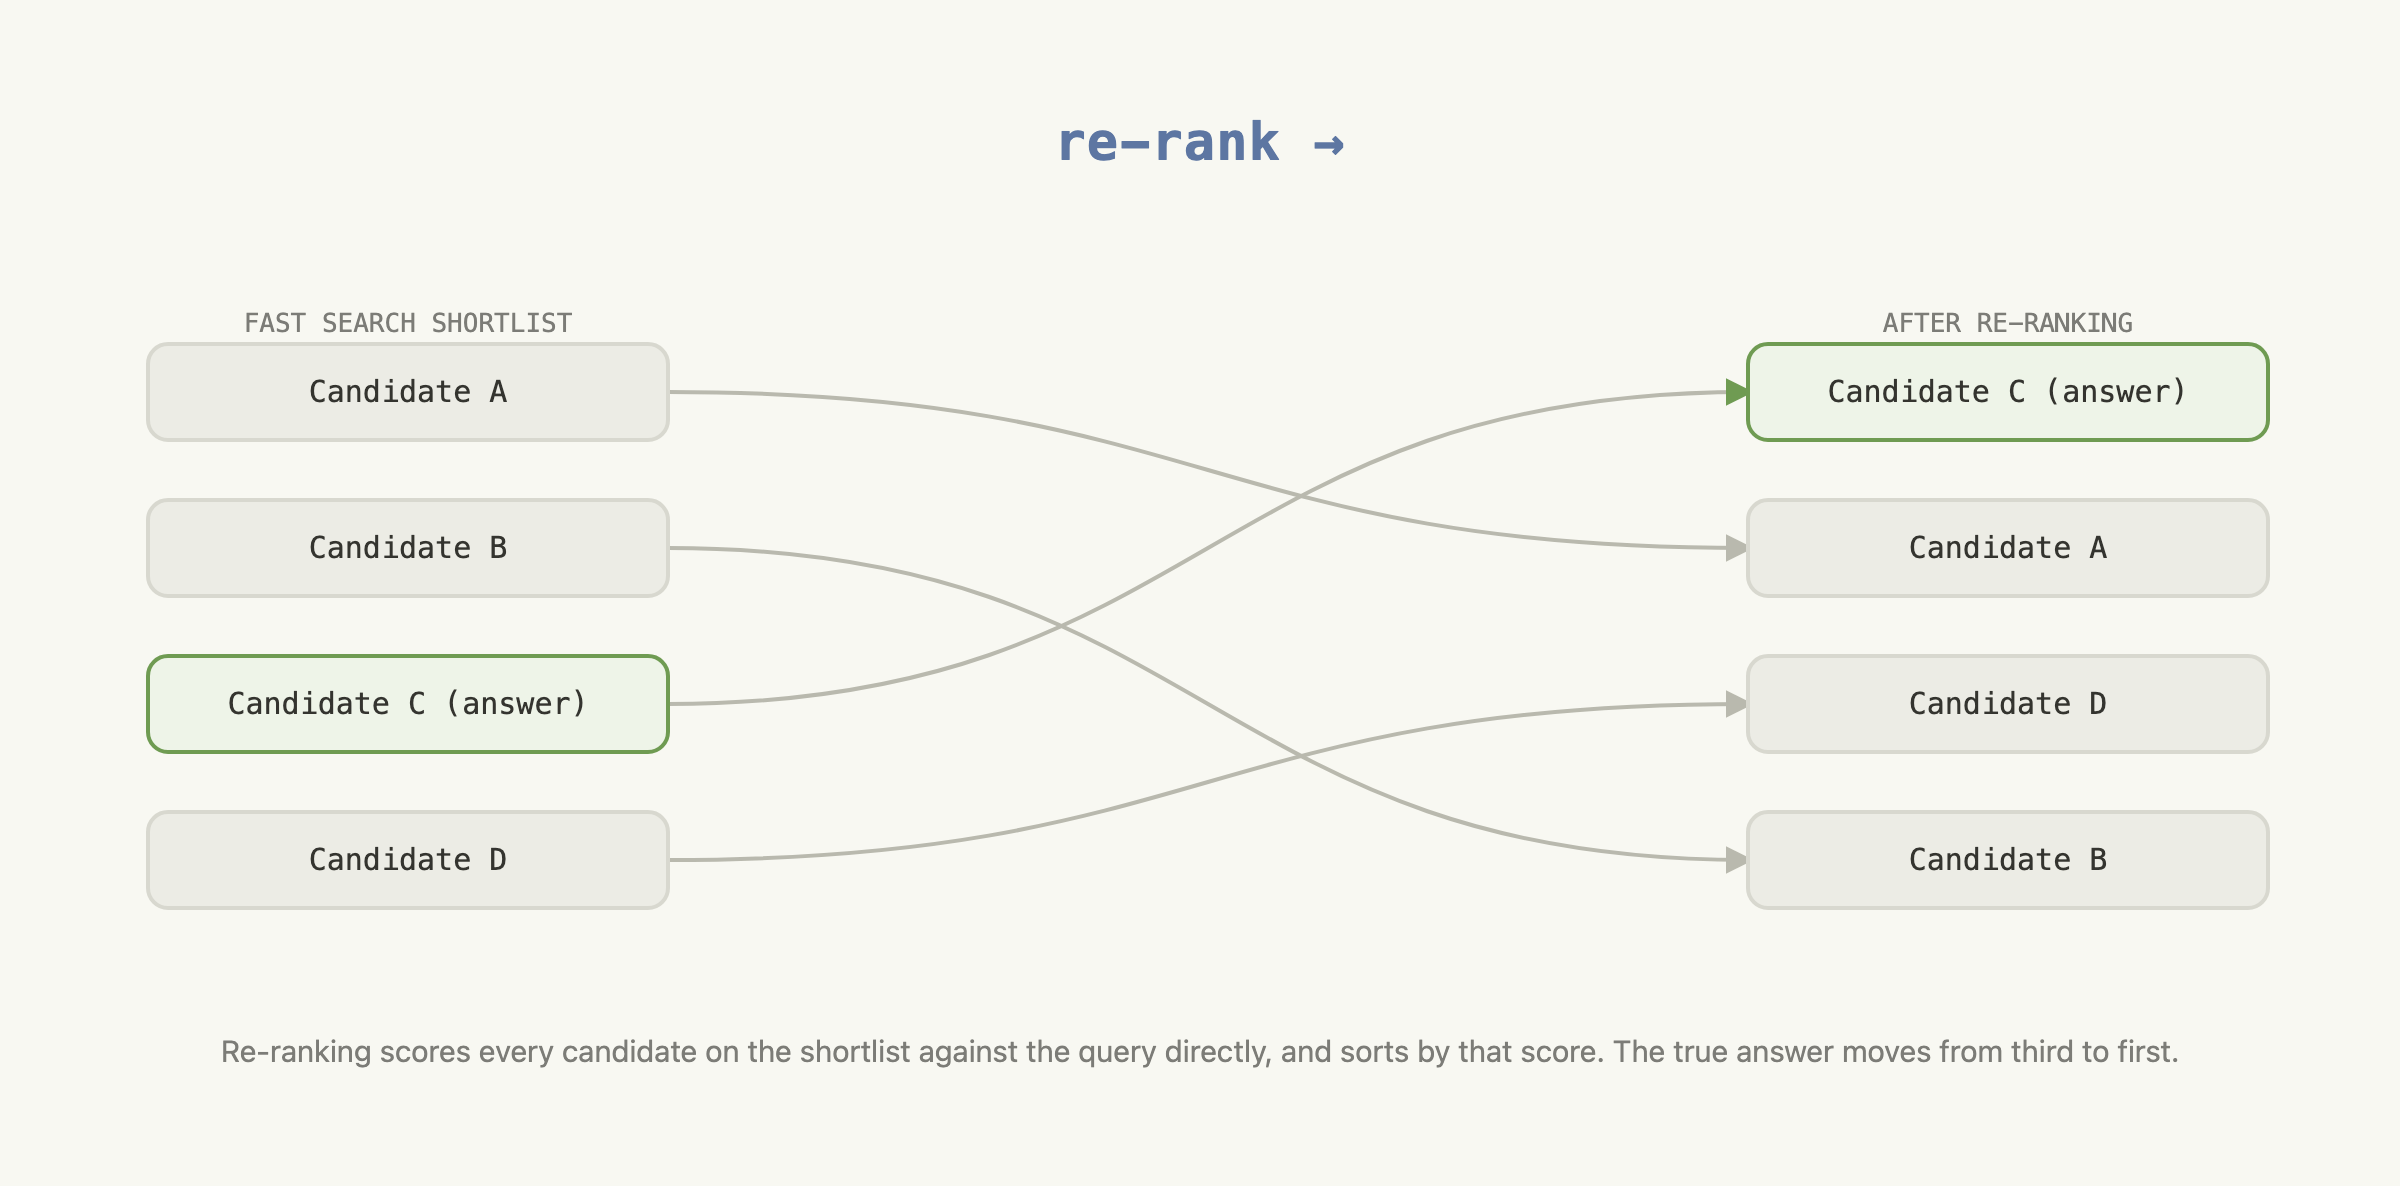

The score can come from a language model. Give it the query and one candidate together
and ask how well the candidate answers the query. Re-ranking then finds the best match
on the shortlist even when its wording differs from the query's.

## Re-ranking with Jev

A re-ranker needs a comparable score for every query-candidate pair.

### What Jev returns

With TypeSafe, the scoring request is a yes/no question:

```text
Could this candidate passage be from the cited precedent?
```

A plain yes or no would not be enough to rank 30 candidates. A `Noul` instead
returns a number between 0 and 1, called a
[noul](https://console.typesafe.ai/docs/primitives/noul). The noul is Jev's estimate
of how likely the answer is to be yes.

The question's criteria define what counts as true and false. Jev applies them to
every query-candidate pair and returns the noul directly. That noul is the score the
application sorts on.

In simplified pseudocode, one TypeSafe scoring call looks like this:

```python title="Sketch"
question = Noul(
    instructions="Is this candidate the cited case?",
    criteria=NoulCriteria(
        true="The candidate states the specific rule the query cites.",
        false="The candidate is only on a similar topic.",
    ),
)
response = client.system_one(state={...}, questions={"is_cited_source": question})
response.answers["is_cited_source"].noul  # -> 0.87
```

To re-rank a shortlist, ask the same question about every candidate and sort by noul,
highest first:

```python title="Sketch"
nouls = {candidate: ask_typesafe(query, candidate) for candidate in shortlist}
reranked = sorted(shortlist, key=lambda c: nouls[c], reverse=True)  # highest noul first
```

```mermaid
flowchart LR
    q["query excerpt<br/><i>one opinion passage,<br/>citation removed</i>"]
    sl["shortlist from fast search"]
    quest["<b>one Noul</b><br/>could this candidate be<br/>from the cited precedent?<br/><i>criteria fix true and false</i>"]

    %% direction LR inside an LR chart keeps each state beside its noul, two columns,
    %% so the fan-out is four rows tall instead of eight
    subgraph fan["one request per candidate · no request sees another"]
        direction LR
        d1["state<br/>{query, candidate 1}"] --> n1["noul<br/>0.87"]
        d2["state<br/>{query, candidate 2}"] --> n2["noul<br/>0.41"]
        dx["⋮"] --> nx["⋮"]
        d30["state<br/>{query, candidate n}"] --> n30["noul<br/>0.12"]
    end

    sort["sort by noul,<br/>highest first"]
    out["re-ranked shortlist<br/><i>same candidates, better order</i>"]

    q --> fan
    sl --> fan
    quest --> fan
    fan --> sort --> out

    %% the elision is not a node, so drop its box and it reads as "and so on"
    classDef elide fill:none,stroke:none
    class dx,nx elide
    linkStyle 2 stroke:none
```

## A re-ranking example

Fast search and re-ranking now run on
[CLERC](https://aclanthology.org/2025.findings-naacl.441/), a legal retrieval dataset.
This example uses 3,565 court opinion passages and 40 queries.

### Setup

- `bm25s` and `datasets` build the fast search shortlist.
- `typesafe-sdk` and `cooksafe` handle re-ranking and API caching.
- `matplotlib` draws the result charts.

```bash
pip install bm25s datasets matplotlib 'cooksafe>=0.3.0,<0.4.0'
```

With uv, `uv run rerank_typesafe.py` installs the dependencies for you.

The code replays saved answers, so it runs as published without an API key. To change a
request, set `TYPESAFE_API_KEY`; in Colab, add it in the Secrets panel.

In [ ]:
%pip install -q bm25s datasets matplotlib 'typesafe-sdk>=0.7.0' ipython 'cooksafe>=0.3.0,<0.4.0'

In [1]:
import hashlib
import json
import os
import random
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from cooksafe import JsonCache, make_playground_link
from IPython.display import Markdown, display
from typesafe_sdk import Noul, NoulCriteria, TypeSafeClient

TYPESAFE_MODEL = "jev-1.14.0"  # the page's model; "jev-latest" runs the newest, live
N_ROWS = 170  # CLERC rows pooled into the shared corpus
N_QUERIES = 40  # rows we evaluate
TOP_K = 30  # candidates the shortlist hands to the re-ranker, per query

# The keys this cookbook uses. In Colab, keys saved in the Secrets panel are copied in here.
KEYS = ["TYPESAFE_API_KEY"]
try:
    from google.colab import userdata
except ImportError:  # not in Colab
    userdata = None
for key in KEYS:
    if userdata is not None and key not in os.environ:
        try:
            os.environ[key] = userdata.get(key)
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            pass  # not saved, or this notebook may not read it

client = TypeSafeClient(
    api_key=os.environ.get(
        "TYPESAFE_API_KEY", "cache-only"
    ),  # keyless kernels replay the cache
    base_url=os.environ.get("TYPESAFE_ENDPOINT"),
    timeout=120.0,
)

In [2]:
EXAMPLES_URL = (
    "https://raw.githubusercontent.com/typesafe-ai/typesafe-public-examples/main/"
    "cookbooks/rerank_typesafe"
)


def download(name: str) -> Path:
    """Fetch one of this cookbook's files from typesafe-public-examples unless it is on disk."""
    path = Path(name)
    if not path.exists():
        urllib.request.urlretrieve(f"{EXAMPLES_URL}/{name}", path)
    return path


CACHE = Path("rerank_typesafe_cache.json")
# True fills CACHE with the published answers, so the run makes no requests. To run
# live, set it to False and delete CACHE; a CACHE already on disk is never overwritten.
DOWNLOAD_CACHE = True
if DOWNLOAD_CACHE:
    download(CACHE.name)
json_cache = JsonCache(CACHE)

### Ranking the passages with fast search

The dataset used here is a corpus of US court opinions, 170 rows pooled together. Each
row breaks down like this:

- **Query**: an opinion excerpt with a citation removed.
- **Gold**: the passage the removed citation pointed to, the one correct answer to the
  query.
- **Candidates**: every other passage in the corpus, each one something the query could be
  matched against by mistake.

Of the 170 rows, 40 are picked to evaluate as queries. The other 130 only ever appear as
candidates.

Fast search loads the corpus and ranks it against every query with BM25. Jev isn't
involved yet.

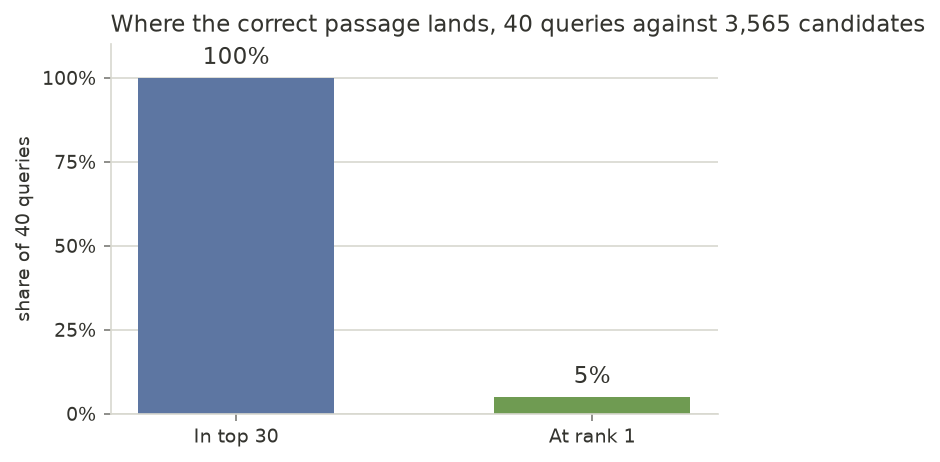

In [3]:
CLERC_FILE = (
    "https://huggingface.co/datasets/jhu-clsp/CLERC/resolve/main/"
    "teva_train_dir/train_data.jsonl.gz"
)


def cid(text: str) -> str:
    """Corpus id: a content hash, so passages shared across queries dedupe."""
    return hashlib.sha1(text.encode("utf-8")).hexdigest()[:16]


@json_cache
def build_slice(n_rows: int, n_queries: int, seed: int) -> dict:
    """Stream CLERC rows, pool ``n_rows`` of them into a corpus, pick ``n_queries`` to evaluate."""
    from datasets import load_dataset  # heavy import, keep local

    stream = load_dataset("json", data_files=CLERC_FILE, streaming=True, split="train")
    rows = []
    for row in stream:
        if (
            row.get("positive_passages")
            and len(row.get("negative_passages") or []) == 20
        ):
            rows.append(row)
        if len(rows) >= 1000:
            break

    rng = random.Random(seed)
    picked = rng.sample(rows, n_rows)
    corpus, pool = {}, []
    for row in picked:
        gold = row["positive_passages"][0]["text"]
        corpus[cid(gold)] = gold
        for neg in row["negative_passages"]:
            corpus[cid(neg["text"])] = neg["text"]
        pool.append(
            {"qid": str(row["query_id"]), "query": row["query"], "gold": cid(gold)}
        )
    # hold out the first 20 pooled rows; evaluate on the rest
    queries = rng.sample(pool[20:], n_queries)
    # sort the corpus by id so every run — live or cache replay — iterates it identically
    return {"queries": queries, "corpus": dict(sorted(corpus.items()))}


def bm25_rankings(corpus: dict[str, str], queries: dict[str, str], k: int = 100):
    """Rank every passage in the corpus by word overlap with each query."""
    import bm25s

    cids = list(corpus)
    retriever = bm25s.BM25()
    retriever.index(bm25s.tokenize([corpus[c] for c in cids], stopwords="en"))
    qids = list(queries)
    idxs, _ = retriever.retrieve(
        bm25s.tokenize([queries[q] for q in qids], stopwords="en"), k=min(k, len(cids))
    )
    return {q: [cids[i] for i in idxs[row]] for row, q in enumerate(qids)}


def gold_rank(ranked: list[str], gold: str) -> int | None:
    """1-based rank of the gold id, or None if it isn't in the list."""
    return ranked.index(gold) + 1 if gold in ranked else None


# The docs page shows each chart matching its light or dark theme; a notebook shows the light one.
PALETTES = {
    "light": {"surface": "#ffffff", "ink": "#34342f", "muted": "#7c7c77", "grid": "#d8d8cf", "blue": "#5d76a2", "green": "#6f9b52"},
    "dark": {"surface": "#0d0a0f", "ink": "#fafafa", "muted": "#a1a1aa", "grid": "#3f3f46", "blue": "#8fa6d6", "green": "#93c47d"},
}


def show(draw) -> None:
    """Display ``draw(palette)`` in the light palette. The docs build sets COOKSAFE_RENDER and
    also gets the dark copy."""
    import matplotlib.pyplot as plt

    for theme in ("light", "dark") if os.environ.get("COOKSAFE_RENDER") else ("light",):
        fig = draw(PALETTES[theme])
        display(fig, metadata={"theme": theme})
        plt.close(fig)


def bar_chart(labels: list[str], shares: list[float], title: str, p: dict):
    """A small single-series bar chart of shares (0-1, shown as percentages)."""
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(5, 3.2), facecolor=p["surface"])
    ax.set_facecolor(p["surface"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(p["grid"])
    ax.tick_params(colors=p["muted"], labelcolor=p["ink"], labelsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=p["grid"], linewidth=0.8)

    bars = ax.bar(labels, shares, width=0.55, color=[p["blue"], p["green"]][: len(labels)])
    ax.bar_label(
        bars,
        labels=[f"{s * 100:.0f}%" for s in shares],
        padding=4,
        color=p["ink"],
        fontsize=11,
    )
    ax.set_ylim(0, 1.1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_ylabel(f"share of {len(queries)} queries", color=p["ink"], fontsize=9)
    ax.set_title(title, loc="left", color=p["ink"], fontsize=11)
    plt.tight_layout()
    return fig


ds = build_slice(N_ROWS, N_QUERIES, seed=0)
corpus: dict[str, str] = ds["corpus"]
queries = {q["qid"]: q["query"] for q in ds["queries"]}
golds = {q["qid"]: q["gold"] for q in ds["queries"]}

candidates = {q: ranked[:TOP_K] for q, ranked in bm25_rankings(corpus, queries).items()}

in_top_k = sum(golds[q] in candidates[q] for q in queries)
at_rank_1 = sum(candidates[q][0] == golds[q] for q in queries)

show(lambda p: bar_chart(
    [f"In top {TOP_K}", "At rank 1"],
    [in_top_k / len(queries), at_rank_1 / len(queries)],
    f"Where the correct passage lands, {len(queries)} queries against {len(corpus):,} candidates",
    p,
))

### Fast search is unlikely to rank the right passage first

The chart shows where fast search puts the correct passage, out of 3,565 candidates.

The shortlist contains the right answer for 100% of the 40 queries, but ranks it first
only 5% of the time.

Re-ranking only reorders the top 30 candidates already on the shortlist. It cannot add a
passage that fast search did not select.

### Re-ranking the shortlist with Jev

The question Jev answers about each pair is whether the candidate could be the passage
the query's removed citation points to. Re-ranking takes three steps:

1. Define that question.
2. Ask it once per candidate on every shortlist: 40 queries times 30 candidates, or 1,200
   calls, run concurrently.
3. Sort each shortlist by the noul Jev returns.

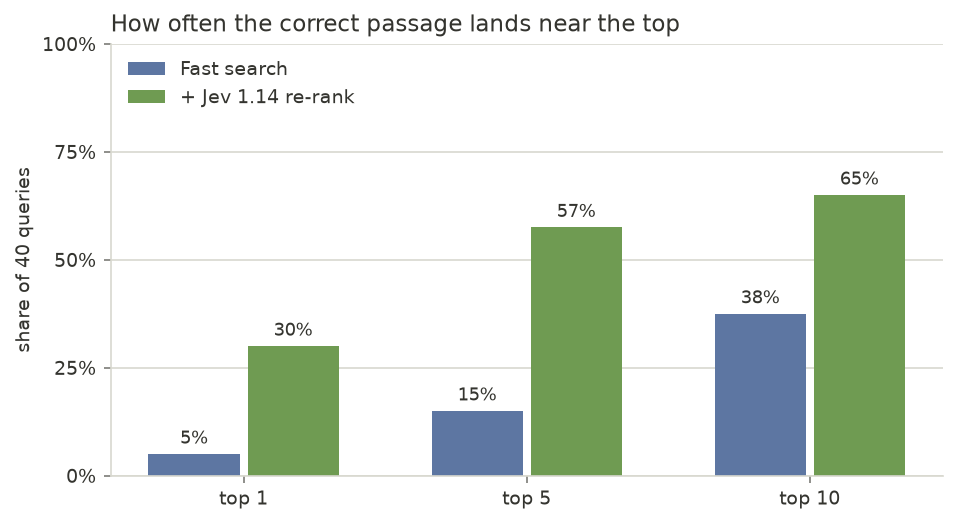

In [4]:
is_cited_source = Noul(
    instructions=(
        "The query excerpt comes from a US federal court opinion and was written "
        "immediately around a citation to a precedent; the citation itself has been "
        "removed. Could the candidate passage be from that cited precedent — does it "
        "establish the specific legal proposition the query excerpt invokes at its "
        "citation point?"
    ),
    criteria=NoulCriteria(
        true=(
            "The candidate passage states or establishes the specific rule, standard, "
            "holding, or fact pattern that the query excerpt attributes to its removed "
            "citation."
        ),
        false=(
            "The candidate passage is merely on a similar topic or doctrine; it does not "
            "supply the specific proposition the query excerpt relies on."
        ),
    ),
)


@json_cache
def score_candidate(query: str, candidate: str, question_json: str, model: str) -> dict:
    """One TypeSafe call about one (query, candidate) pair: a noul, plus token usage."""
    # the SDK takes a question as its JSON dict, so the cached string decodes straight in
    question = json.loads(question_json)
    response = client.system_one(
        state={"query_excerpt": query, "candidate_passage": candidate},
        questions={"is_cited_source": question},
        model=model,
    )
    return {
        "noul": response.answers["is_cited_source"].noul,
        "input_tokens": response.usage.input_tokens or 0,
        "output_tokens": response.usage.output_tokens or 0,
    }


# Each of the 40 queries has 30 candidates, so re-ranking every shortlist means 1,200 independent
# calls, cheap enough to fire all at once with a thread pool instead of one after another.
pair_list = [(q, c) for q in queries for c in candidates[q]]
question_json = is_cited_source.model_dump_json(exclude_none=True)
with ThreadPoolExecutor(max_workers=12) as pool:
    results = pool.map(
        lambda p: score_candidate(
            queries[p[0]], corpus[p[1]], question_json, model=TYPESAFE_MODEL
        ),
        pair_list,
    )
pair_scores = {q: {} for q in queries}
for (q, c), result in zip(pair_list, results):
    pair_scores[q][c] = result

reranked = {
    q: sorted(candidates[q], key=lambda c: -pair_scores[q][c]["noul"]) for q in queries
}


def chart_before_after(
    runs: dict[str, dict[str, list[str]]], thresholds: list[int], p: dict
):
    """Grouped bar chart: how often the correct passage lands in the top N, for each run."""
    import numpy as np
    import matplotlib.pyplot as plt

    labels = list(runs)
    colors = [p["blue"], p["green"]]

    def share_in_top(rankings, k):
        return sum(
            gold_rank(rankings[q], golds[q]) in range(1, k + 1) for q in queries
        ) / len(queries)

    fig, ax = plt.subplots(figsize=(6.5, 3.6), facecolor=p["surface"])
    ax.set_facecolor(p["surface"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(p["grid"])
    ax.tick_params(colors=p["muted"], labelcolor=p["ink"], labelsize=9)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=p["grid"], linewidth=0.8)

    x = np.arange(len(thresholds))
    width = 0.35
    for i, (label, rankings) in enumerate(runs.items()):
        shares = [share_in_top(rankings, k) for k in thresholds]
        offset = (i - (len(labels) - 1) / 2) * width
        bars = ax.bar(x + offset, shares, width * 0.92, color=colors[i], label=label)
        ax.bar_label(
            bars,
            labels=[f"{s * 100:.0f}%" for s in shares],
            padding=3,
            color=p["ink"],
            fontsize=8.5,
        )

    ax.set_xticks(x, [f"top {k}" for k in thresholds])
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_yticklabels(["0%", "25%", "50%", "75%", "100%"])
    ax.set_ylabel(f"share of {len(queries)} queries", color=p["ink"], fontsize=9)
    ax.set_title(
        "How often the correct passage lands near the top",
        loc="left",
        color=p["ink"],
        fontsize=11,
    )
    ax.legend(frameon=False, labelcolor=p["ink"], fontsize=9, loc="upper left")
    plt.tight_layout()
    return fig


show(lambda p: chart_before_after(
    {"Fast search": candidates, "+ Jev 1.14 re-rank": reranked}, [1, 5, 10], p
))

### Re-ranking moves the right answer toward the top

The chart compares fast search against fast search plus re-ranking, at three thresholds.
Re-ranking moves the correct passage closer to the top at every one of them:

- **Top 1**: 5% → 30%
- **Top 5**: 15% → 57%
- **Top 10**: 38% → 65%

This walkthrough asked one question per pair for clarity. A real application would
ask several questions about the same pair in one call. See the [parallel questions
cookbook](https://console.typesafe.ai/docs/cookbooks/parallel_questions) and the
[Speculative fan-out pattern](https://console.typesafe.ai/docs/patterns/fan-out) for how.

## Open it in the playground

The link holds one query excerpt, the passage it cites, and the question. Fast search
ranked that passage below first place; re-ranking put it first.

In [5]:
example = next(q for q in queries if reranked[q][0] == golds[q] != candidates[q][0])
playground_link = make_playground_link(
    {"query_excerpt": queries[example], "candidate_passage": corpus[golds[example]]},
    {"is_cited_source": is_cited_source},
)
display(Markdown(f"🔗 [Open in the TypeSafe playground]({playground_link})"))

🔗 [Open in the TypeSafe playground](https://console.typesafe.ai/playground#share/N4IgJg9gxgrgtgUwHYBcAqCAeKQC4AEIwAOiAI4wIBOAngPpZTUAOKpBpAjAAz4DCASyoA6ADT4AnAGZ8AMWEAmMPgAcAVl4AKJAgDu+AIYwUEfMwNUUAZ3FWEUCEjABaABYGnh46fOWrASgBufABBABsAMyoEZQARGCRXATCw-AgI-AAZR0gkcQBJJChhfAA3EvjE5NSAZSTLfDqIZgKisXxY4T52mXlGmGZmEoAWFQB2fE0rOAgAa2orQEwCfCsB5jCBBBsV+usg-ABxaIMUUJQwjxQBKHwAMnwABQMoAQjr-AwDfggS8tCS+4PEp8MIIDwLO4dGgLcSdbriHhyYQ1NYjDSTADmVGg1BoKxM0XEUFBHgESAx+C2KAMACMNlZXIhUPsjmDTiFzpd3oDnq93p9vr8SiEAY8SgAlAxgASmGoEratYqwrrtBS8eQowYlMbcGSaLE4qibKzBKhSmXbXQGBlkilwZ5JHTbDzKBCgqAoI03aJRAQY6gnCBUAIlTRQfyPeyuBAwKhZCAAL2Q-sFZRKADkTjKkAZUnwXXi+D9bAMzcEatBHDRnAA1Z4weD4ADyyVTf3FEDseXwADZ+EJ2jwVEilL2pApgrIIGFEHGjgYIqDMN8qMwg1nHGnDmbmEkbg9XBATI1qKVrggS8wzSUABIeCClaiNalxgCy1VtbZKr4QKCguYicQFGGXgAFVkRGXVxCkPsai6FASikNQxnEHteEyYQAFEwG1TgpGCF18HwcVMNiEI+DQUj8AER98CNDFXGsaikHwT0pQQZx7SoWYrBKAAhYxWOjOx8H-OwrGY0pp0fZRHDCPE5ROBBRIgOAZhYi59DYsAEC4njxCQI9WLNHTOIsHi6IQDEBCsFBqBifAEh0uMUGjUIPTSDJOAkbg1GFTwyXwCJnlOVzlM1aJEG+WNTlWDF-VshzArC4j7GpJAYAksTlNck5vnJaIrAk6VlHcWiUrXXRqBKGoEGUgAtDYkFmdJAPwTCjWUv40FU5hZjJKwCEKVKLiuTdjxSzIDH0dIPhMjjX3MiTCNApBgqEb44GYX8BDGljNG84YFAjI7vjCYQMPFBA-gkNQ1HECQxhQ-AkBKHySnyWLDxgMJlBpZTDLs5RctCtyeGcaELFEi5MuUwKAHL8DUMxqDgXaJOiazbLNPbPJWVTlL0iTAZUpArAEZyHO0jiicMU4HDUzdNNsMkmCEhA8V0IMAaM1YaQAKzS5j2aCoRbOY2yPDZ49GDCTKaOUgxBmxK8BA3V78FW5yRcUuylhUxmNOmvGEnWuMGe2q49tEUhxFIf8nAppS6HMIqDH9dh8FIdbXMpLawggaFlC+am9OFxxwupOzxEImk8RS2G8d2-B3D+mBklOAZDGM9j2cJfB-s-FK3mDU4lavZojUDONkvcU5+djGzpQ9bNxDRhiy4iOyqCtKgwAk-6zGiR9UAcqJVMc8nyWolBxF0XbXFJuwKGQU4yQb2hWNMJIJOpwxPAxCAIBceeUhj0G4bJ9K2dmiP8F0Q889-dJuZTqU-fWQOqbcqwDCisOaSCTkniQKR5oxxkIpFI8ykN5N2uHtbYAxxpuQNE5ISeV0ai1Lh-AONAmSnHcIMZAVNTCXBiEpdBpxZrFzFigTiq9sxU3miIfAw07CPjNKkbKEkIgxADFwiAMUJJlWUtGX6lDs6qyDJPZSs0Q7zTMtxYWXwIjcz9CxBwCRPR4hKi9IyDDzhwyYhAXQOgXKmGJAYAQcBKSYGJPLcqCiw70UYhJWuylVq7QcrrLYhhloYisVfNIOh76P0CofY+QUrG+1ToYSArAHJfA2PMHOpkw7gOUlI8xItV6b2oW5VR0R1FPjJBNHe+A9K-glNcRiT4-ghCKIeOMV1EBgELMWJGCg5AxAlAgIY+Bhh3XEIMlQwRxQ1O7luK6NBDK-W2GoCQ3ScKpX6chZ6yEJDBAAOq5kmXxAw8w4z3CLEKDobolbIHcAiNCSzen9LGMMHs4gHmjMOEGdwNjXwRAxMCH4W4tkIFKWaGANIEQSB7CUWQPSVlvWQg9HsnAShoB-n-TJEBSn4GEFaNxSApJhBksLO8hkOH4HfCkT8Jytw-j-ABICIFNY1UglIYZnB7qhPsvfZSv8KYEEADgEhQSgpSDNKHMm9sp418FcXxFsdrTyck+FKv9-7mXwOIdxKxUUVPMr+NVa8spBmiB5Y8v9451yHjKCBytK5q1xnYFAhjd5uRXrZbM-FBIPw5SgLmZgLBSpxTpbaThV7yUMNEHBgci4ouVUopBLEIn9zxq5AAlxqqKliiriEAWvFidhfAUMqUxB+04Q1QLsiLO+48bFCrClQcQKVnW41mlkwwVrVbq2ohJUEASUggLJuovkDtZ6OSQKCIqdN8AknFsncuYIXJmsVfYHIcTmjd3EO4CSdh3RAxFmHeevsrAE3wDpcmGIWJkmsdcXMW8RalPsrZCS+TlIl3FnAOwtaVgwCgIva017qQpJSv9HQbwqEZBStEZgxh22zXKfGk017ClUlzKkFKWA7J9s3NBmyqSLxpDncpZJCBhCAFwCVhLFXJYeyjHZaYRjhtMspUsAdaMkdr0R++KVJsx4y+FPGykyIOrk7LIsjblJV4yuh6DwmVcOYpSuJ9KUmixbQ8DQYI0Yig5RE9aX+KYKDQOUA4Kghrzg6IQG8J0ItJYoCk4+n1lhjTmukSYQVbkrhRQ9fnMKeJ-xRVKRAAgMqracfVQAaVXp+2YeIC3+WUMnQqP1rBUezjoJgbtN5kl4dEdTpAAC+IBxAgArltawGBsB4EICQEANk6AvCBnQA9sYmCewqygGg21PakEMj9W2XtKtXyoJ+hB7WQDIuUivTejAWD0wJjw7ENivigRqEFPhnCVIxTSMwc9m5CLYvvkae1yBqJqRiDat0eILCCM8F8Gr7bjxfCvPYPhqBggpWu7jdGboMjroLnVFiUCZK-J+sDNyDsSoUNdtp5Sg9K0SJqw5e7TAdKoHwIAFAIj0QF8cnRDdIbKL0VdtF4bwbhdqvRXNc5Ncb1soONuxk3JJzF8Rgpir3ONrlKQAfm6-bPb1A1ZNdIJ6SgQ2RuiRdE7Mt4P3Zcqjr46RWP6TCQs-jgddEfo4clk4CwjGU7ThFRicQ0jgoeXMPtqgwm8qU9xLYpgq4y72qNFm3xx5MF-YcszxwwhOcgGCmEOwQvgei7AGDrTkuWOzlO8E7O5M0YXHMRtm40jIAeiNDoYIydIC+JJqsQYIa8f2GV6Tzsu1OMW+p9b1glkNgy9ejl7LuX8tKwEDWBY2YysgFKJwEA2WgA)

----------------

## What's next

- [Noul](https://console.typesafe.ai/docs/primitives/noul), for how Jev turns a yes/no
  question into a score.
- [Speculative fan-out](https://console.typesafe.ai/docs/patterns/fan-out), for asking
  several questions about one document in a single call.
- [Line-by-line Search](https://console.typesafe.ai/docs/cookbooks/semantic_find),
  for another way to search a corpus by meaning rather than keywords.